In [8]:
%pip install -q ucimlrepo pandas numpy scikit-learn matplotlib seaborn joblib streamlit tabulate

Note: you may need to restart the kernel to use updated packages.


In [15]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [17]:
# UCI Machine Learning Repository: Dry Bean dataset (ID 602)
dry_bean = fetch_ucirepo(id=602)

X = dry_bean.data.features.copy()
y_raw = dry_bean.data.targets.iloc[:, 0].copy()

# Remove rows with missing values, if any, keeping X and y aligned.
valid_rows = X.notna().all(axis=1) & y_raw.notna()
X = X.loc[valid_rows].reset_index(drop=True)
y_raw = y_raw.loc[valid_rows].reset_index(drop=True)

# Encode class names as integers for consistent multiclass metric handling.
label_encoder = LabelEncoder()
y = pd.Series(label_encoder.fit_transform(y_raw.astype(str)), name="Class")

FEATURE_NAMES = X.columns.tolist()
TARGET_COLUMN = "Class"
CLASS_NAMES = label_encoder.classes_.tolist()

print(f"Rows: {X.shape[0]}")
print(f"Features: {X.shape[1]}")
print(f"Classes: {len(CLASS_NAMES)}")
print("Class names:", CLASS_NAMES)

assert X.shape[0] >= 500, "Dataset does not meet the 500-row requirement."
assert X.shape[1] >= 12, "Dataset does not meet the 12-feature requirement."
assert y.nunique() >= 2, "Classification requires at least two classes."

display(X.head())
display(y.value_counts().sort_index().rename("Count").to_frame())

Rows: 13611
Features: 16
Classes: 7
Class names: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166


,Count
Class,
0,1322
1,522
2,1630
3,3546
4,1928
5,2027
6,2636


Dataset information:


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860154
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRatio,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


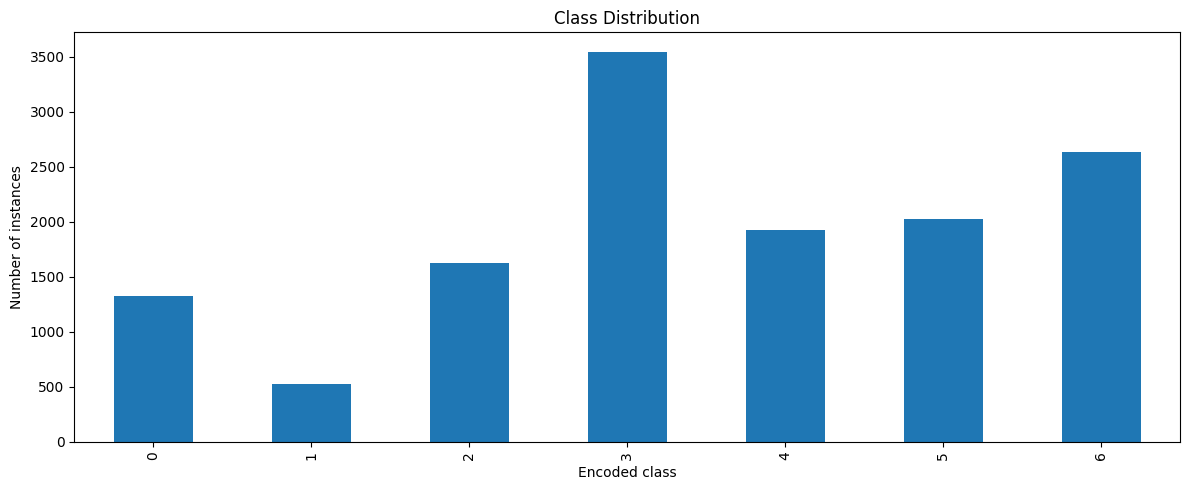

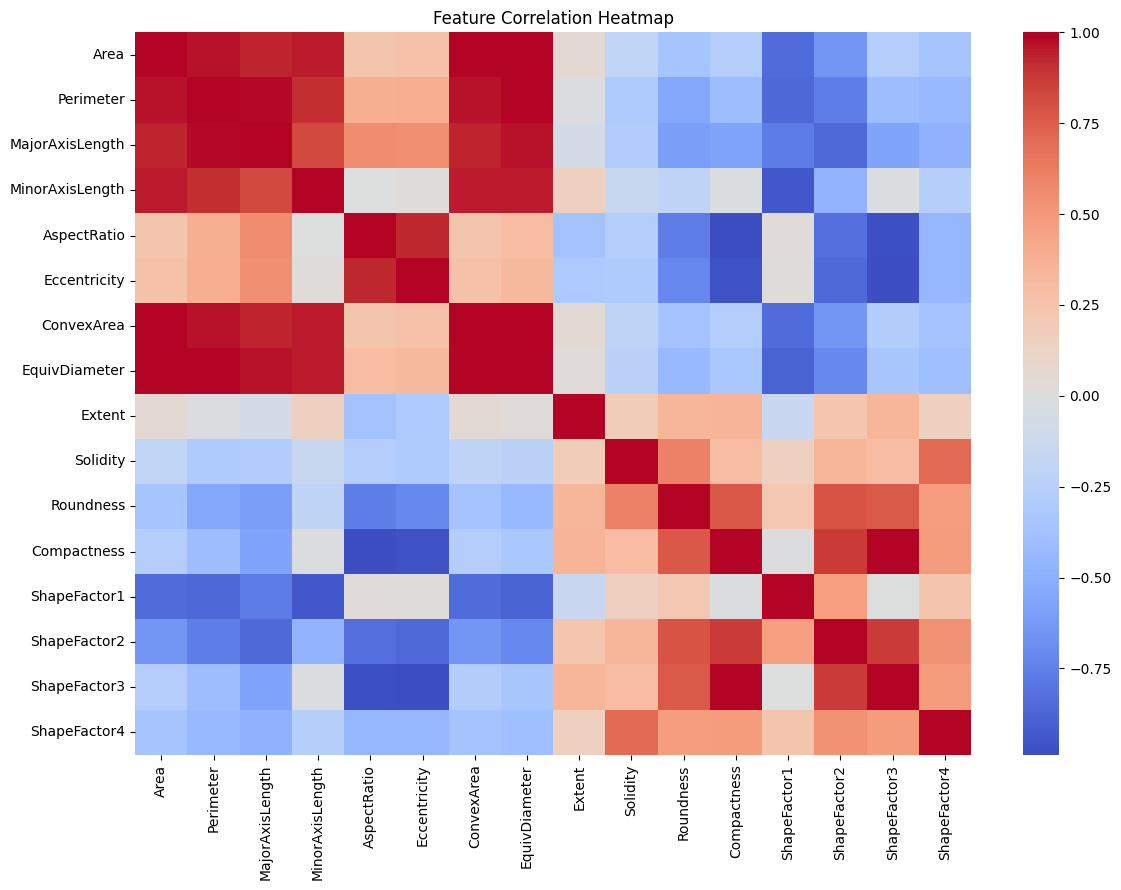

In [19]:
print("Dataset information:")
display(X.describe().T)

plt.figure(figsize=(12, 5))
y.value_counts().sort_index().plot(kind="bar")
plt.title("Class Distribution")
plt.xlabel("Encoded class")
plt.ylabel("Number of instances")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 9))
sns.heatmap(X.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (10888, 16)
Testing features: (2723, 16)
Training labels: (10888,)
Testing labels: (2723,)


In [23]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        class_weight=None
    ),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Gaussian Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", GaussianNB())
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))
    ])
}

print("Models defined:", list(models.keys()))

Models defined: ['Logistic Regression', 'Decision Tree', 'KNN', 'Gaussian Naive Bayes', 'SVM']


In [25]:
trained_models = {}
results = []
prediction_store = {}

for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)

    trained_models[model_name] = model
    prediction_store[model_name] = y_pred

    model_classes = model.classes_
    auc = roc_auc_score(
        y_test,
        y_proba,
        labels=model_classes,
        multi_class="ovr",
        average="weighted"
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": auc,
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

metrics_df = pd.DataFrame(results).sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

display(metrics_df.round(4))

Training Logistic Regression...
Training Decision Tree...
Training KNN...
Training Gaussian Naive Bayes...
Training SVM...


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,SVM,0.9221,0.9937,0.9224,0.9221,0.9222,0.9059
1,Logistic Regression,0.9207,0.9934,0.9215,0.9207,0.9209,0.9042
2,KNN,0.9166,0.9812,0.9174,0.9166,0.9168,0.8992
3,Gaussian Naive Bayes,0.8979,0.9902,0.9007,0.8979,0.8981,0.8773
4,Decision Tree,0.8917,0.9330,0.8912,0.8917,0.8913,0.8691


In [27]:

for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train, y_train)
    trained_models[model_name] = model

print("Models trained:", list(trained_models.keys()))
print("Total models:", len(trained_models))

Training Logistic Regression...
Training Decision Tree...
Training KNN...
Training Gaussian Naive Bayes...
Training SVM...
Models trained: ['Logistic Regression', 'Decision Tree', 'KNN', 'Gaussian Naive Bayes', 'SVM']
Total models: 5


In [29]:
import joblib
from pathlib import Path

OUTPUT_DIR = Path("dry_bean_assignment_output")
MODEL_DIR = OUTPUT_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save all five trained models
for model_name, model in trained_models.items():

    safe_name = model_name.lower().replace(" ", "_")
    file_path = MODEL_DIR / f"{safe_name}.joblib"

    joblib.dump(model, file_path)

    print("Saved:", file_path)

print("\nAll models saved successfully.")

Saved: dry_bean_assignment_output/models/logistic_regression.joblib
Saved: dry_bean_assignment_output/models/decision_tree.joblib
Saved: dry_bean_assignment_output/models/knn.joblib
Saved: dry_bean_assignment_output/models/gaussian_naive_bayes.joblib
Saved: dry_bean_assignment_output/models/svm.joblib

All models saved successfully.


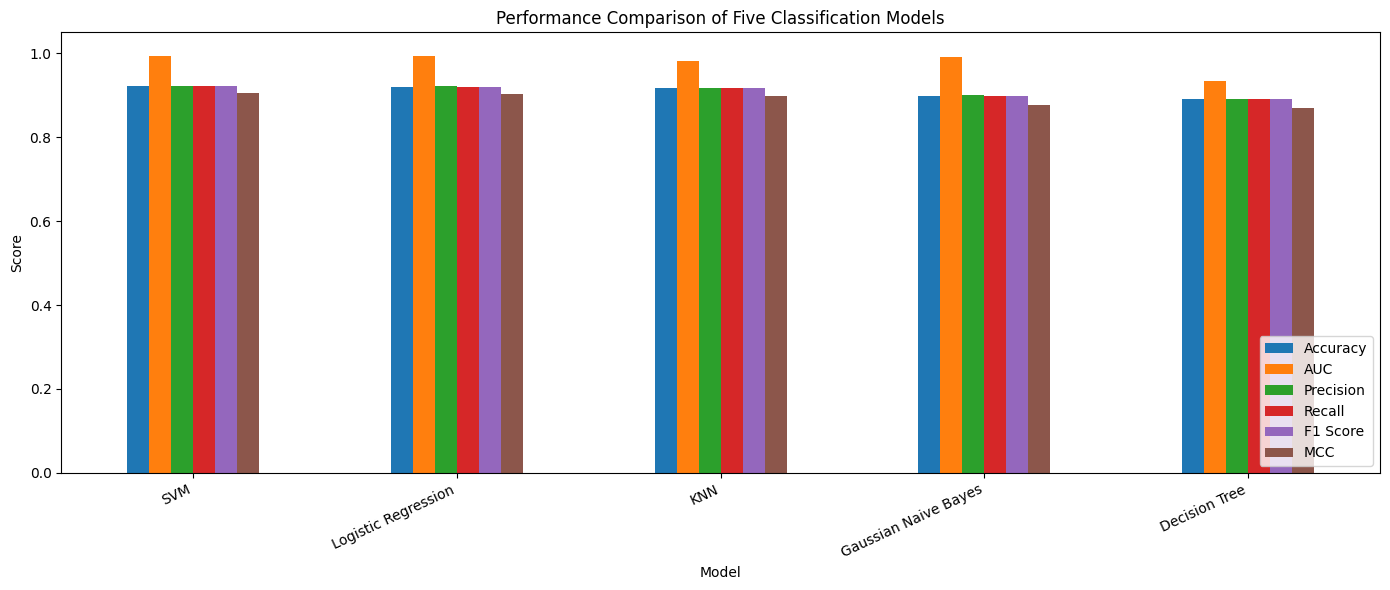

In [31]:
metric_columns = ["Accuracy", "AUC", "Precision", "Recall", "F1 Score", "MCC"]

ax = metrics_df.set_index("Model")[metric_columns].plot(
    kind="bar", figsize=(14, 6), ylim=(0, 1.05)
)
ax.set_title("Performance Comparison of Five Classification Models")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

MODEL: Logistic Regression
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.94      0.94       326
    DERMASON       0.92      0.91      0.92       709
       HOROZ       0.96      0.95      0.96       386
       SEKER       0.93      0.95      0.94       406
        SIRA       0.85      0.88      0.86       527

    accuracy                           0.92      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



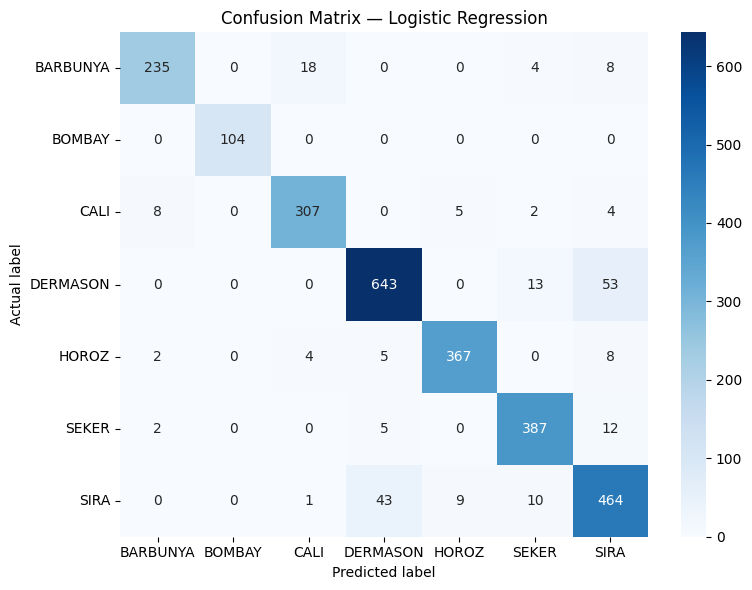

MODEL: Decision Tree
              precision    recall  f1-score   support

    BARBUNYA       0.89      0.90      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.92      0.92       326
    DERMASON       0.88      0.89      0.88       709
       HOROZ       0.94      0.92      0.93       386
       SEKER       0.91      0.94      0.92       406
        SIRA       0.83      0.79      0.81       527

    accuracy                           0.89      2723
   macro avg       0.91      0.91      0.91      2723
weighted avg       0.89      0.89      0.89      2723



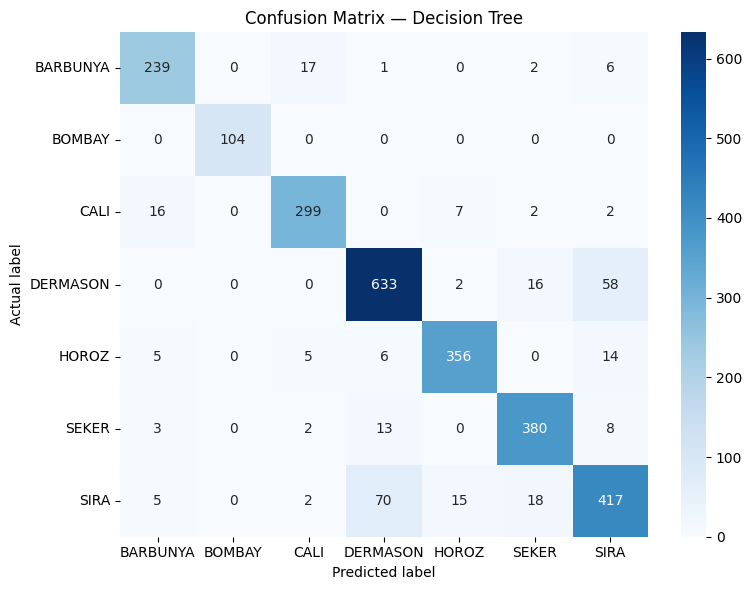

MODEL: KNN
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.88      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.91      0.91      0.91       709
       HOROZ       0.95      0.95      0.95       386
       SEKER       0.95      0.94      0.95       406
        SIRA       0.84      0.87      0.86       527

    accuracy                           0.92      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



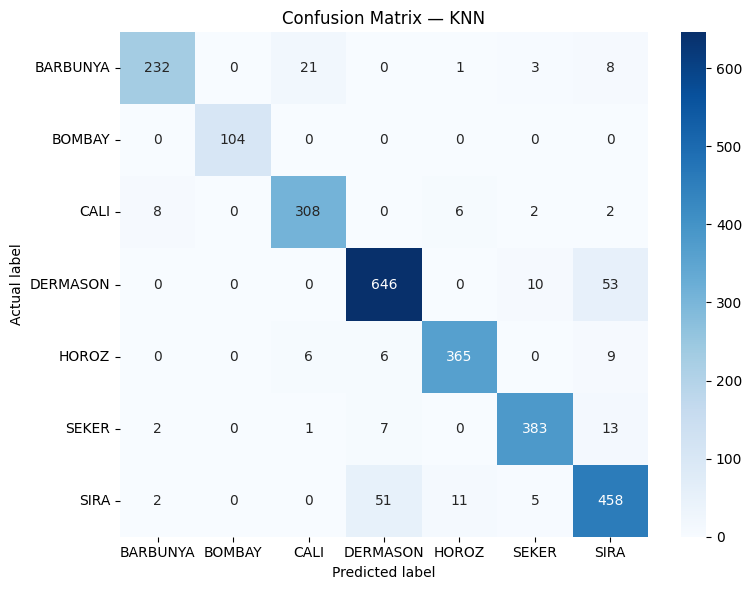

MODEL: Gaussian Naive Bayes
              precision    recall  f1-score   support

    BARBUNYA       0.90      0.80      0.85       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.86      0.92      0.89       326
    DERMASON       0.93      0.86      0.90       709
       HOROZ       0.95      0.95      0.95       386
       SEKER       0.92      0.94      0.93       406
        SIRA       0.81      0.89      0.84       527

    accuracy                           0.90      2723
   macro avg       0.91      0.91      0.91      2723
weighted avg       0.90      0.90      0.90      2723



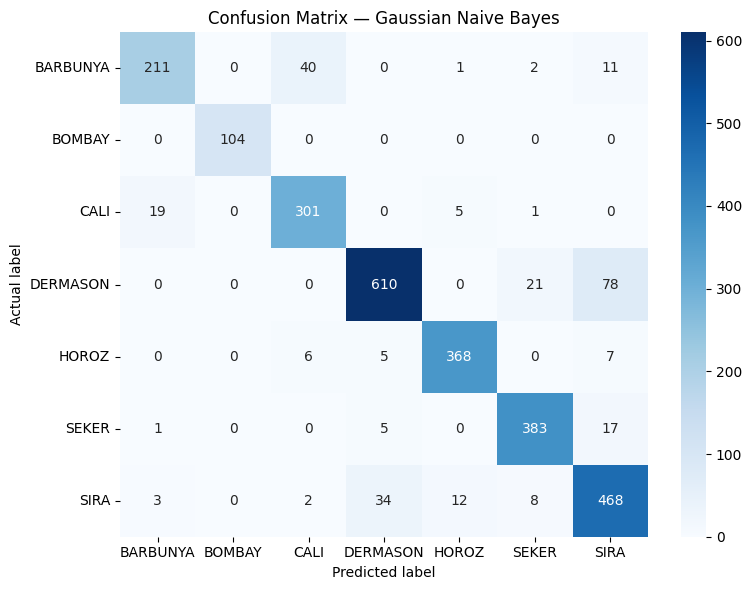

MODEL: SVM
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.95      0.94       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.96      0.96       386
       SEKER       0.94      0.95      0.94       406
        SIRA       0.86      0.87      0.87       527

    accuracy                           0.92      2723
   macro avg       0.94      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



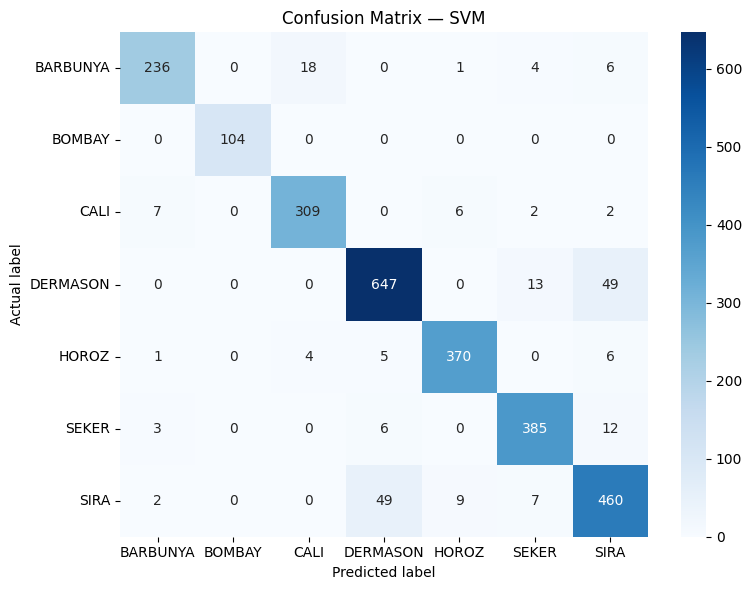

In [33]:
for model_name, y_pred in prediction_store.items():
    print("=" * 80)
    print(f"MODEL: {model_name}")
    print(classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(CLASS_NAMES)),
        target_names=CLASS_NAMES,
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(CLASS_NAMES)))
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
    )
    plt.title(f"Confusion Matrix — {model_name}")
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    plt.tight_layout()
    plt.show()

In [35]:
best_model_name = metrics_df.iloc[0]["Model"]
best_model_f1 = metrics_df.iloc[0]["F1 Score"]

print("Best model based on weighted F1 Score:", best_model_name)
print(f"Weighted F1 Score: {best_model_f1:.4f}")

print("\nUse the actual results above to write your observations.")
print("Do not claim that one model is best on every metric unless the table supports that conclusion.")

Best model based on weighted F1 Score: SVM
Weighted F1 Score: 0.9222

Use the actual results above to write your observations.
Do not claim that one model is best on every metric unless the table supports that conclusion.


In [37]:
OUTPUT_DIR = Path("dry_bean_assignment_output")
MODEL_DIR = OUTPUT_DIR / "models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save all five fitted models.
for model_name, fitted_model in trained_models.items():
    safe_name = model_name.lower().replace(" ", "_")
    joblib.dump(fitted_model, MODEL_DIR / f"{safe_name}.joblib")

# Save metrics and labelled test data.
metrics_df.to_csv(OUTPUT_DIR / "metrics.csv", index=False)

test_data = X_test.copy()
test_data[TARGET_COLUMN] = y_test.map(
    {index: class_name for index, class_name in enumerate(CLASS_NAMES)}
)
test_data.to_csv(OUTPUT_DIR / "test_data.csv", index=False)

metadata = {
    "feature_names": FEATURE_NAMES,
    "target_column": TARGET_COLUMN,
    "class_names": CLASS_NAMES,
    "model_names": list(trained_models.keys()),
    "best_model_name_by_weighted_f1": best_model_name,
    "random_state": RANDOM_STATE
}
with open(OUTPUT_DIR / "metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print("Saved artifacts to:", OUTPUT_DIR.resolve())
print("Saved model files:", sorted(path.name for path in MODEL_DIR.glob("*.joblib")))
print("Saved test data:", OUTPUT_DIR / "test_data.csv")

Saved artifacts to: /home/s2026ak05564/workspace/dry_bean_assignment_output
Saved model files: ['decision_tree.joblib', 'gaussian_naive_bayes.joblib', 'knn.joblib', 'logistic_regression.joblib', 'svm.joblib']
Saved test data: dry_bean_assignment_output/test_data.csv


In [39]:
import joblib
from pathlib import Path

OUTPUT_DIR = Path("dry_bean_assignment_output")
MODEL_DIR = OUTPUT_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save all five trained models
for model_name, model in trained_models.items():

    safe_name = model_name.lower().replace(" ", "_")
    file_path = MODEL_DIR / f"{safe_name}.joblib"

    joblib.dump(model, file_path)

    print("Saved:", file_path)

print("\nAll models saved successfully.")

Saved: dry_bean_assignment_output/models/logistic_regression.joblib
Saved: dry_bean_assignment_output/models/decision_tree.joblib
Saved: dry_bean_assignment_output/models/knn.joblib
Saved: dry_bean_assignment_output/models/gaussian_naive_bayes.joblib
Saved: dry_bean_assignment_output/models/svm.joblib

All models saved successfully.


In [41]:
app_code = r'''from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import streamlit as st
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix, classification_report
)

BASE_DIR = Path(__file__).resolve().parent
MODEL_DIR = BASE_DIR / "models"

with open(BASE_DIR / "metadata.json", "r", encoding="utf-8") as file:
    metadata = json.load(file)

FEATURE_NAMES = metadata["feature_names"]
TARGET_COLUMN = metadata["target_column"]
CLASS_NAMES = metadata["class_names"]
MODEL_NAMES = metadata["model_names"]

@st.cache_resource
def load_models():
    loaded = {}
    for name in MODEL_NAMES:
        filename = name.lower().replace(" ", "_") + ".joblib"
        loaded[name] = joblib.load(MODEL_DIR / filename)
    return loaded

st.set_page_config(page_title="Dry Bean Classifier", layout="wide")
st.title("Dry Bean Classification")
st.write("Upload a labelled CSV with the required features and target column to evaluate a saved model.")

uploaded_file = st.file_uploader("Upload labelled test CSV", type=["csv"])
selected_model_name = st.selectbox("Choose a trained model", MODEL_NAMES)

if uploaded_file is not None:
    data = pd.read_csv(uploaded_file)
    required_columns = FEATURE_NAMES + [TARGET_COLUMN]
    missing_columns = [column for column in required_columns if column not in data.columns]

    if missing_columns:
        st.error("Missing required columns: " + ", ".join(missing_columns))
    elif data.empty:
        st.error("The uploaded CSV is empty.")
    else:
        X_upload = data[FEATURE_NAMES].copy()
        y_text = data[TARGET_COLUMN].astype(str)

        class_to_index = {name: index for index, name in enumerate(CLASS_NAMES)}
        unknown_classes = sorted(set(y_text) - set(class_to_index))

        if unknown_classes:
            st.error("Unknown target class values: " + ", ".join(unknown_classes))
        else:
            y_true = y_text.map(class_to_index).to_numpy()
            model = load_models()[selected_model_name]
            y_pred = model.predict(X_upload)
            y_probability = model.predict_proba(X_upload)

            score_values = {
                "Accuracy": accuracy_score(y_true, y_pred),
                "Precision (weighted)": precision_score(y_true, y_pred, average="weighted", zero_division=0),
                "Recall (weighted)": recall_score(y_true, y_pred, average="weighted", zero_division=0),
                "F1 Score (weighted)": f1_score(y_true, y_pred, average="weighted", zero_division=0),
                "MCC": matthews_corrcoef(y_true, y_pred)
            }

            try:
                score_values["AUC (weighted OVR)"] = roc_auc_score(
                    y_true, y_probability,
                    labels=model.classes_,
                    multi_class="ovr",
                    average="weighted"
                )
            except ValueError:
                score_values["AUC (weighted OVR)"] = float("nan")
                st.warning("AUC could not be calculated. The uploaded data may not contain every class.")

            st.subheader("Evaluation metrics")
            st.dataframe(pd.DataFrame([score_values]).round(4), use_container_width=True)

            st.subheader("Confusion matrix")
            cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(CLASS_NAMES)))
            cm_df = pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES)
            st.dataframe(cm_df, use_container_width=True)

            st.subheader("Classification report")
            report = classification_report(
                y_true, y_pred,
                labels=np.arange(len(CLASS_NAMES)),
                target_names=CLASS_NAMES,
                output_dict=True,
                zero_division=0
            )
            st.dataframe(pd.DataFrame(report).transpose().round(4), use_container_width=True)
else:
    st.info("Upload a labelled CSV to view evaluation results.")
'''
(OUTPUT_DIR / "app.py").write_text(app_code, encoding="utf-8")
print("Created Streamlit app:", OUTPUT_DIR / "app.py")

Created Streamlit app: dry_bean_assignment_output/app.py


In [43]:
requirements_text = """streamlit
pandas
numpy
scikit-learn
joblib
matplotlib
seaborn
ucimlrepo
tabulate
"""

(OUTPUT_DIR / "requirements.txt").write_text(requirements_text, encoding="utf-8")
print("Created:", OUTPUT_DIR / "requirements.txt")

Created: dry_bean_assignment_output/requirements.txt


In [45]:
readme = f"""# Dry Bean Classification — ML Assignment 2

## Problem Statement
Predict the variety of a dry bean using its geometrical measurements.

## Dataset
- Source: UCI Machine Learning Repository — Dry Bean
- Number of instances: {len(X)}
- Number of features: {X.shape[1]}
- Number of classes: {y.nunique()}

## Models
- Logistic Regression
- Decision Tree
- K-Nearest Neighbors (KNN)
- Gaussian Naive Bayes
- Support Vector Machine (SVM)

## Evaluation Metrics
Precision, Recall, and F1 Score use weighted averaging.
Multiclass AUC uses weighted one-vs-rest ROC AUC.

## Model Comparison

{metrics_df.round(4).to_markdown(index=False)}

## Best Model
The model with the highest weighted F1 Score in this run is **{best_model_name}**.

## Observations
Write a short, evidence-based observation for each model using the comparison table and confusion matrices. Explain any trade-offs; do not assume the best model wins every metric.

## Run Locally
1. Install dependencies: `pip install -r requirements.txt`
2. Start the app: `streamlit run app.py`

## GitHub Repository
Replace this line with your GitHub repository URL.

## Live Streamlit Application
Replace this line with your Streamlit Community Cloud URL.
"""

readme_path = OUTPUT_DIR / "README.md"
readme_path.write_text(readme, encoding="utf-8")
print("README.md created successfully:", readme_path.resolve())

README.md created successfully: /home/s2026ak05564/workspace/dry_bean_assignment_output/README.md


In [47]:
saved_models = list(MODEL_DIR.glob("*.joblib"))

print("Model files found:")

for model_file in saved_models:
    print(model_file.name)

print("\nTotal saved models:", len(saved_models))

assert len(saved_models) == 5, (
    f"Expected 5 models, but found {len(saved_models)}"
)

print("\nAll five models verified successfully!")

Model files found:
gaussian_naive_bayes.joblib
svm.joblib
logistic_regression.joblib
decision_tree.joblib
knn.joblib

Total saved models: 5

All five models verified successfully!
